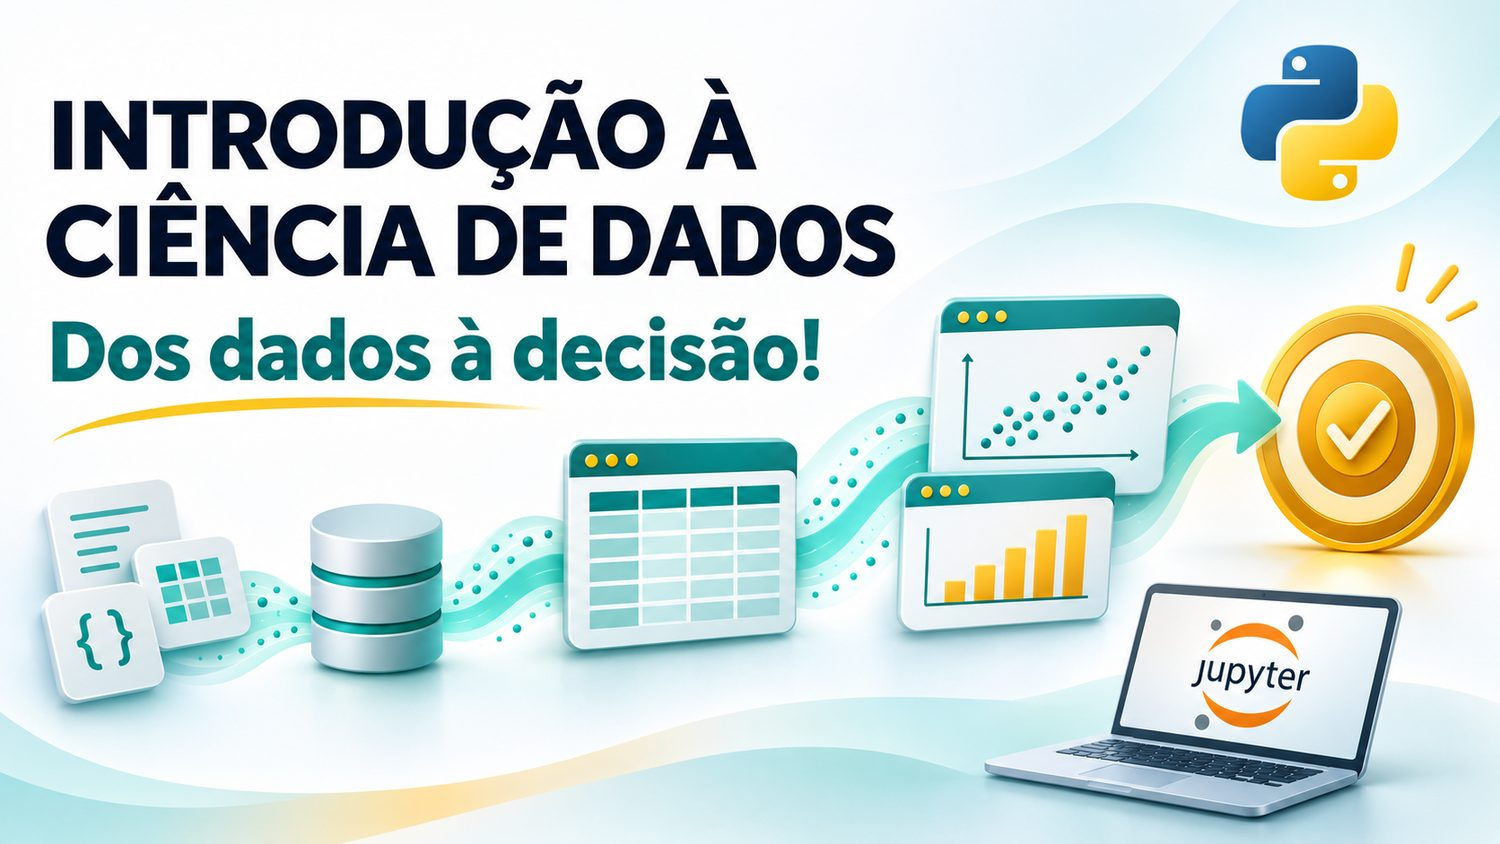

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/05_Sobreajuste_Vies_e_Variancia.ipynb)

# Capítulo 5 – Sobreajuste, viés e variância

Nos três capítulos anteriores apareceu sempre o mesmo desenho: à medida que o modelo fica mais complexo, o desempenho no treino melhora sem parar, e o desempenho em dados novos melhora, atinge um ponto ótimo e depois piora. Este capítulo explica porquê. A explicação tem dois nomes, **viés** e **variância**, e é a ideia mais importante para diagnosticar e corrigir um modelo que não funciona.

> **Objetivos:** distinguir subajuste de sobreajuste; perceber que um modelo complexo pode memorizar ruído; decompor o erro em viés, variância e ruído, e medir cada parte por simulação; diagnosticar um modelo a partir dos erros de treino e de validação; ler curvas de aprendizagem; escolher o remédio certo para cada problema.

**Pré-requisitos:** capítulos 1 a 4, e o capítulo 2 do módulo 4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## Um mundo em que conhecemos a verdade

Com dados reais nunca sabemos qual é a relação verdadeira: só vemos as observações. Para estudar o sobreajuste, é útil trabalhar num mundo simulado em que a conhecemos.

Imagina as entregas de 6 km para o centro, feitas de mota. O tempo **esperado** depende só da hora de saída: é maior nas horas de ponta. Cada entrega concreta desvia-se do esperado por razões que nenhum atributo capta (um semáforo, um elevador avariado). A esse desvio chamamos **ruído**.

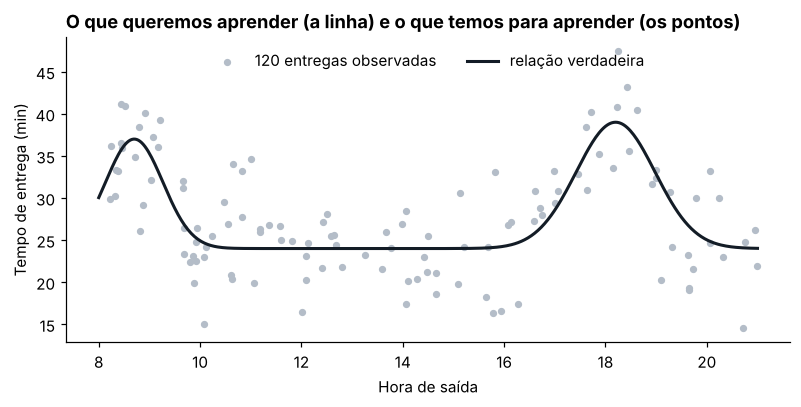

In [2]:
def tempo_esperado(hora):
    """A relação verdadeira, que na vida real nunca conhecemos."""
    hora = np.asarray(hora, dtype=float)
    return 24 + 13 * np.exp(-((hora - 8.7) / 0.8) ** 2) + 15 * np.exp(-((hora - 18.2) / 1.1) ** 2)


RUIDO = 5.0                                    # desvio-padrão do ruído, em minutos


def amostrar(n, rng):
    """Gera n entregas: hora de saída e tempo observado (verdade + ruído)."""
    hora = np.sort(rng.uniform(8, 21, n))
    return hora.reshape(-1, 1), tempo_esperado(hora) + rng.normal(0, RUIDO, n)


rng = np.random.default_rng(11)
X, y = amostrar(120, rng)
horas = np.linspace(8, 21, 400).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.scatter(X, y, s=14, color=CINZA, label="120 entregas observadas")
ax.plot(horas, tempo_esperado(horas), color=TINTA, lw=2, label="relação verdadeira")
ax.set_xlabel("Hora de saída")
ax.set_ylabel("Tempo de entrega (min)")
ax.set_title("O que queremos aprender (a linha) e o que temos para aprender (os pontos)")
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.show()

O objetivo de um modelo é recuperar a **linha preta** a partir dos **pontos cinzentos**. A dificuldade é que os pontos misturam duas coisas: o padrão, que se repete em dados novos, e o ruído, que não se repete.

## Três modelos: simples de mais, complexo de mais, e no ponto

Treinamos três árvores de regressão com os mesmos 120 pontos, e avaliamo-las em 5 000 entregas novas.

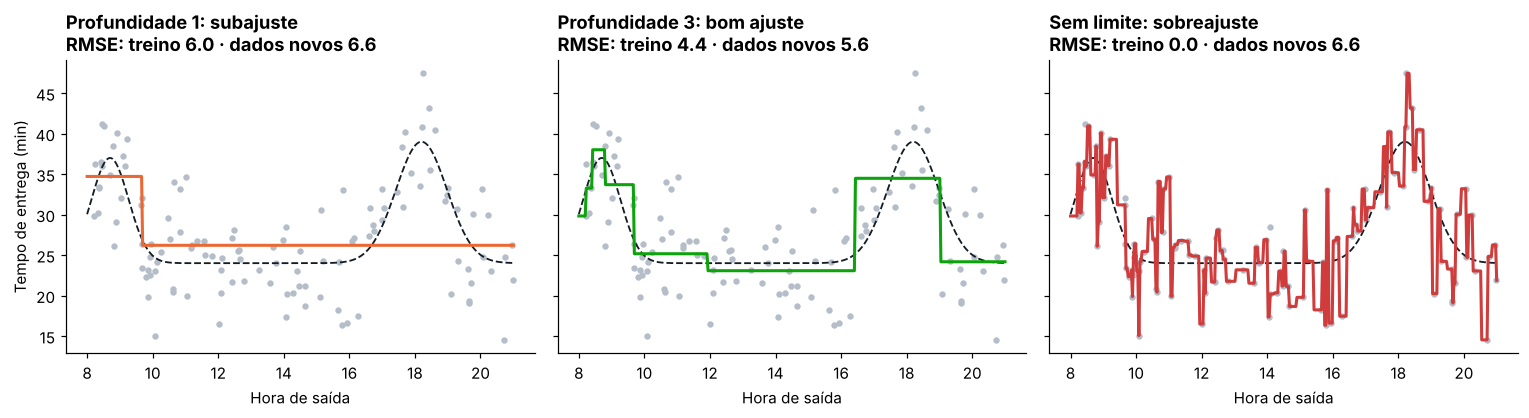

In [3]:
from sklearn.tree import DecisionTreeRegressor

X_novo, y_novo = amostrar(5000, np.random.default_rng(99))
casos = [(1, "Profundidade 1: subajuste", LARANJA), (3, "Profundidade 3: bom ajuste", BOM), (None, "Sem limite: sobreajuste", MAU)]

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, (profundidade, titulo, cor) in zip(eixos, casos):
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=0).fit(X, y)
    erro_treino = np.sqrt(np.mean((y - arvore.predict(X)) ** 2))
    erro_novo = np.sqrt(np.mean((y_novo - arvore.predict(X_novo)) ** 2))
    ax.scatter(X, y, s=10, color=CINZA)
    ax.plot(horas, tempo_esperado(horas), color=TINTA, lw=1.2, ls="--")
    ax.plot(horas, arvore.predict(horas), color=cor, lw=2)
    ax.set_title(f"{titulo}\nRMSE: treino {erro_treino:.1f} · dados novos {erro_novo:.1f}")
    ax.set_xlabel("Hora de saída")
eixos[0].set_ylabel("Tempo de entrega (min)")
plt.tight_layout()
plt.show()

| | Subajuste (*underfitting*) | Bom ajuste | Sobreajuste (*overfitting*) |
| --- | --- | --- | --- |
| O modelo é | Demasiado simples para o padrão | Adequado | Demasiado flexível para os dados que tem |
| No desenho | Ignora uma das horas de ponta | Segue a linha tracejada | Passa por todos os pontos |
| Erro no treino | Alto | Perto do ruído | Zero |
| Erro em dados novos | Alto | O mais baixo | Alto |
| Aprendeu | Menos do que o padrão | O padrão | O padrão **e o ruído** |

Repara no modelo do meio: o seu erro em dados novos fica perto de 5 minutos, que é o desvio-padrão do ruído. Nenhum modelo pode fazer melhor do que isso. O ruído é, por definição, a parte que não se consegue prever.

O modelo da direita tem erro **zero** no treino e é pior do que o do meio em dados novos. Decorou as 120 entregas, incluindo o semáforo e o elevador de cada uma.

## Um modelo flexível aprende o que lhe derem, até ruído puro

Para ver até onde vai a capacidade de memorizar, uma experiência: **baralhamos o alvo**. Cada entrega fica com o tempo de outra, ao acaso. Deixa de haver qualquer relação entre a hora e o tempo.

In [4]:
y_baralhado = np.random.default_rng(5).permutation(y)
linhas = []
for profundidade in [1, 3, None]:
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=0).fit(X, y_baralhado)
    r2_treino = arvore.score(X, y_baralhado)
    linhas.append({"Árvore": "sem limite" if profundidade is None else f"profundidade {profundidade}", "R² no treino": r2_treino, "R² em dados novos": arvore.score(X_novo, y_novo)})
pd.DataFrame(linhas).set_index("Árvore").round(2)

,R² no treino,R² em dados novos
Árvore,,
profundidade 1,0.03,0.02
profundidade 3,0.12,-0.09
sem limite,1.00,-0.89


Não há nada para aprender, e a árvore sem limite consegue mesmo assim um R² de 1 no treino. Em dados novos, é pior do que prever a média (R² negativo).

> **Um bom resultado no treino prova que o modelo é flexível. Não prova que aprendeu alguma coisa.**

## Porque acontece: viés e variância

A amostra de treino é uma entre muitas possíveis (módulo 1, capítulo 5). Com outras 120 entregas, o modelo treinado seria outro. Vamos repetir o treino com 200 amostras diferentes e desenhar 40 dos modelos obtidos.

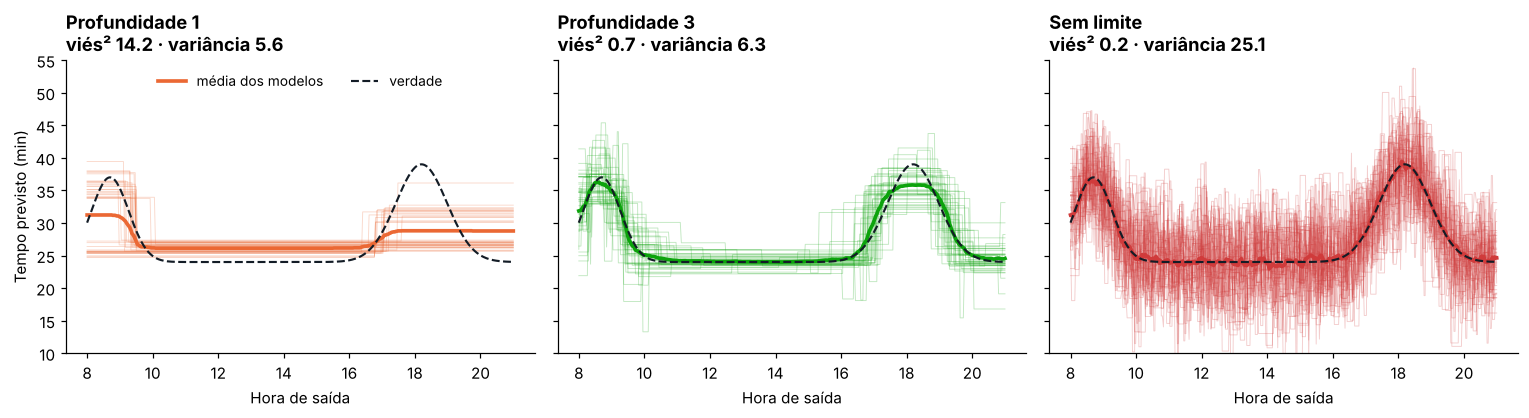

In [5]:
def muitos_modelos(profundidade, repeticoes=200, n=120, semente=0):
    """Treina a mesma árvore em muitas amostras diferentes e devolve todas as curvas de previsão."""
    gerador = np.random.default_rng(semente)
    return np.array([DecisionTreeRegressor(max_depth=profundidade, random_state=0).fit(*amostrar(n, gerador)).predict(horas) for _ in range(repeticoes)])


verdade = tempo_esperado(horas.ravel())
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, (profundidade, titulo, cor) in zip(eixos, casos):
    curvas = muitos_modelos(profundidade)
    for curva in curvas[:40]:
        ax.plot(horas, curva, color=cor, lw=0.6, alpha=0.25)
    ax.plot(horas, curvas.mean(axis=0), color=cor, lw=2.4, label="média dos modelos")
    ax.plot(horas, verdade, color=TINTA, lw=1.4, ls="--", label="verdade")
    ax.set_title(titulo.split(":")[0] + f"\nviés² {np.mean((curvas.mean(axis=0) - verdade) ** 2):.1f} · variância {np.mean(curvas.var(axis=0)):.1f}")
    ax.set_xlabel("Hora de saída")
    ax.set_ylim(10, 55)
eixos[0].set_ylabel("Tempo previsto (min)")
eixos[0].legend(frameon=False, loc="upper center", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

Cada linha fina é um modelo, treinado com uma amostra diferente. A linha grossa é a média de todos.

- **À esquerda**, os modelos são parecidos uns com os outros, mas a sua média está **longe da verdade**: falha sistematicamente uma das horas de ponta e achata a outra. O erro não depende da amostra; vem das limitações do modelo. Chama-se **viés** (*bias*).
- **À direita**, a média dos modelos acompanha a verdade, mas cada modelo individual anda **muito longe da média**: depende imenso da amostra que lhe calhou. Chama-se **variância**.
- **Ao centro**, um compromisso: um pouco de cada.

| | Viés | Variância |
| --- | --- | --- |
| Pergunta | Em média, o modelo acerta? | O modelo muda muito de amostra para amostra? |
| Causa | Modelo demasiado simples; atributos em falta | Modelo demasiado flexível para a quantidade de dados |
| Corresponde a | Subajuste | Sobreajuste |
| Imagem do alvo | Tiros agrupados, longe do centro | Tiros espalhados à volta do centro |

Na prática só temos **uma** amostra e treinamos **um** modelo: uma das linhas finas. Com muito viés, essa linha está errada da mesma maneira que todas as outras. Com muita variância, está errada à sua maneira particular.

### O erro tem três partes

O erro quadrático esperado de um modelo, em dados novos, decompõe-se exatamente em três parcelas:

> **Erro = viés² + variância + ruído**

O ruído é fixo. As outras duas parcelas dependem do modelo, e puxam em sentidos opostos.

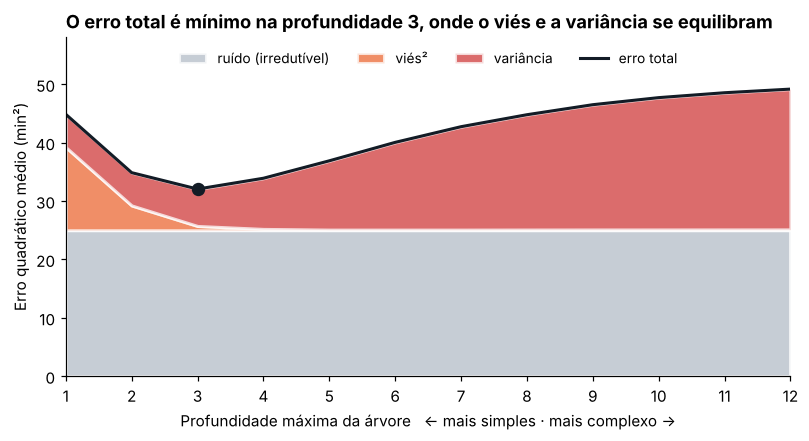

In [6]:
profundidades = list(range(1, 13))
partes = []
for p in profundidades:
    curvas = muitos_modelos(p)
    partes.append({"profundidade": p, "viés²": np.mean((curvas.mean(axis=0) - verdade) ** 2), "variância": np.mean(curvas.var(axis=0))})
partes = pd.DataFrame(partes).set_index("profundidade")
partes["ruído"] = RUIDO ** 2
partes["erro total"] = partes.sum(axis=1)
otima = int(partes["erro total"].idxmin())

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.stackplot(partes.index, partes["ruído"], partes["viés²"], partes["variância"], colors=[CINZA, LARANJA, MAU], alpha=0.75,
             labels=["ruído (irredutível)", "viés²", "variância"], edgecolor="white", linewidth=2)
ax.plot(partes.index, partes["erro total"], color=TINTA, lw=2, label="erro total")
ax.scatter([otima], [partes.loc[otima, "erro total"]], color=TINTA, s=60, zorder=3)
ax.set_xticks(profundidades)
ax.set_xlim(1, 12)
ax.set_xlabel("Profundidade máxima da árvore   ← mais simples · mais complexo →")
ax.set_ylabel("Erro quadrático médio (min²)")
ax.set_title(f"O erro total é mínimo na profundidade {otima}, onde o viés e a variância se equilibram")
ax.legend(frameon=False, loc="upper center", ncol=4, fontsize=9)
ax.set_ylim(0, partes["erro total"].max() * 1.18)
plt.show()

Este gráfico é a explicação do «U» que vimos nos capítulos 2, 3 e 4.

- À esquerda, o erro é dominado pelo **viés**: o modelo é pobre.
- Aumentando a complexidade, o viés cai depressa.
- A partir de certo ponto o viés já é pequeno, e a **variância** continua a crescer. O erro total volta a subir.
- O **ruído** está sempre lá: é o chão abaixo do qual nenhum modelo desce.

Não é possível reduzir as duas parcelas ao mesmo tempo só mexendo na complexidade: é o **compromisso entre viés e variância**. Escolher um hiperparâmetro (k, a profundidade) é escolher um ponto neste compromisso.

## Diagnosticar com os dados que temos

Com dados reais não podemos repetir o treino em 200 amostras nem conhecemos a verdade. Mas temos dois números que dizem quase o mesmo: o **erro de treino** e o **erro de validação**.

| Erro de treino | Erro de validação | Diagnóstico | Parcela dominante |
| --- | --- | --- | --- |
| Alto | Alto, parecido com o de treino | **Subajuste** | Viés |
| Baixo | Muito mais alto do que o de treino | **Sobreajuste** | Variância |
| Baixo | Baixo, parecido com o de treino | Bom ajuste | Nenhuma |
| Alto | Ainda mais alto | Os dois problemas | Ambas |

«Alto» e «baixo» medem-se em relação à linha de base e ao que se sabe do ruído. A **distância entre os dois erros** é o sinal mais útil: uma distância grande indica variância.

Aplicamos às entregas, com os modelos dos capítulos anteriores.

In [7]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


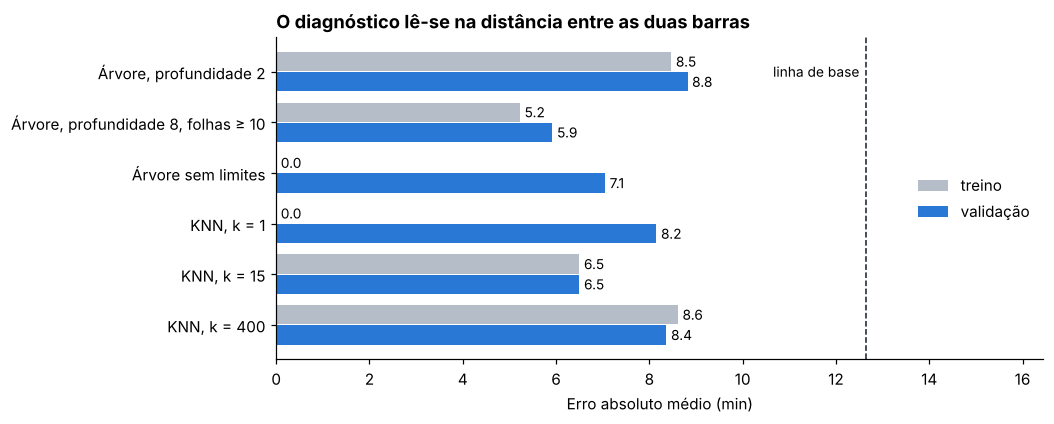

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

treino, resto = train_test_split(entregas, test_size=0.4, random_state=0)
validacao, teste = train_test_split(resto, test_size=0.5, random_state=0)
numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
todas = numericas + nominais


def com_preparacao(modelo):
    return make_pipeline(ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(), nominais)]), modelo)


modelos = {"Árvore, profundidade 2": com_preparacao(DecisionTreeRegressor(max_depth=2, random_state=0)),
           "Árvore, profundidade 8, folhas ≥ 10": com_preparacao(DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0)),
           "Árvore sem limites": com_preparacao(DecisionTreeRegressor(random_state=0)),
           "KNN, k = 1": com_preparacao(KNeighborsRegressor(1)),
           "KNN, k = 15": com_preparacao(KNeighborsRegressor(15)),
           "KNN, k = 400": com_preparacao(KNeighborsRegressor(400))}
linha_de_base = mean_absolute_error(validacao["tempo_min"], np.full(len(validacao), treino["tempo_min"].median()))
diagnostico = []
for nome, modelo in modelos.items():
    modelo.fit(treino[todas], treino["tempo_min"])
    diagnostico.append({"Modelo": nome, "treino": mean_absolute_error(treino["tempo_min"], modelo.predict(treino[todas])),
                        "validação": mean_absolute_error(validacao["tempo_min"], modelo.predict(validacao[todas]))})
diagnostico = pd.DataFrame(diagnostico).set_index("Modelo")

fig, ax = plt.subplots(figsize=(9, 3.8))
posicoes = np.arange(len(diagnostico))
b1 = ax.barh(posicoes - 0.2, diagnostico["treino"], 0.38, color=CINZA, label="treino")
b2 = ax.barh(posicoes + 0.2, diagnostico["validação"], 0.38, color=AZUL, label="validação")
ax.bar_label(b1, fmt="%.1f", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.1f", padding=3, fontsize=9)
ax.axvline(linha_de_base, color=TINTA, ls="--", lw=1)
ax.text(linha_de_base - 0.15, 0, "linha de base", ha="right", va="center", fontsize=9)
ax.set_xlim(0, linha_de_base * 1.3)
ax.set_yticks(posicoes, diagnostico.index)
ax.invert_yaxis()
ax.set_xlabel("Erro absoluto médio (min)")
ax.set_title("O diagnóstico lê-se na distância entre as duas barras")
ax.legend(frameon=False, loc="center right")
plt.show()

- **Árvore de profundidade 2** e **KNN com k = 400**: os dois erros são altos e quase iguais. Subajuste. Dar-lhes mais dados não adiantaria.
- **Árvore sem limites** e **KNN com k = 1**: erro de treino quase nulo e erro de validação alto. Sobreajuste.
- **Os dois modelos intermédios**: os erros mais baixos na validação, com uma distância pequena para o treino.

Uma distância pequena entre treino e validação **não** quer dizer que o modelo é bom: os modelos em subajuste têm a menor distância de todos. É preciso olhar para os dois números.

## Curvas de aprendizagem: mais dados ajudam?

Uma **curva de aprendizagem** mostra o erro em função da **quantidade de dados de treino**. Responde a uma pergunta muito prática: vale a pena recolher mais dados?

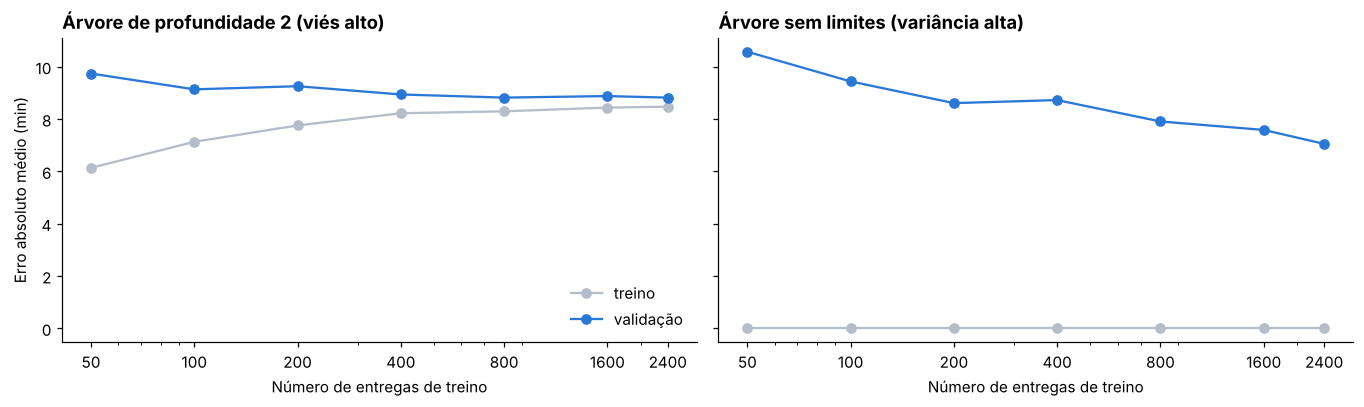

In [9]:
tamanhos = [50, 100, 200, 400, 800, 1600, 2400]
candidatos = {"Árvore de profundidade 2 (viés alto)": lambda: com_preparacao(DecisionTreeRegressor(max_depth=2, random_state=0)),
              "Árvore sem limites (variância alta)": lambda: com_preparacao(DecisionTreeRegressor(random_state=0))}

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, (nome, criar) in zip(eixos, candidatos.items()):
    erros_treino, erros_validacao = [], []
    for n in tamanhos:
        e_t, e_v = [], []
        for semente in range(8):
            parte = treino.sample(n, random_state=semente)
            modelo = criar().fit(parte[todas], parte["tempo_min"])
            e_t.append(mean_absolute_error(parte["tempo_min"], modelo.predict(parte[todas])))
            e_v.append(mean_absolute_error(validacao["tempo_min"], modelo.predict(validacao[todas])))
        erros_treino.append(np.mean(e_t))
        erros_validacao.append(np.mean(e_v))
    ax.plot(tamanhos, erros_treino, "o-", color=CINZA, label="treino")
    ax.plot(tamanhos, erros_validacao, "o-", color=AZUL, label="validação")
    ax.set_xscale("log")
    ax.set_xticks(tamanhos, tamanhos)
    ax.set_xlabel("Número de entregas de treino")
    ax.set_title(nome)
eixos[0].set_ylabel("Erro absoluto médio (min)")
eixos[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

- **Viés alto** (esquerda): as duas curvas aproximam-se depressa e estabilizam num erro alto. A partir de algumas centenas de entregas, **mais dados não mudam nada**. O modelo já aprendeu tudo o que consegue aprender.
- **Variância alta** (direita): o erro de treino fica colado ao zero e o de validação desce devagar, sem parar. As curvas continuam afastadas, e **mais dados continuam a ajudar**.

Antes de pedir mais dados (que custam tempo e dinheiro), vale a pena desenhar esta curva.

## O remédio depende do diagnóstico

| Se o problema é **viés** (subajuste) | Se o problema é **variância** (sobreajuste) |
| --- | --- |
| Usar um modelo mais flexível (k menor, árvore mais funda) | Usar um modelo mais simples (k maior, árvore menos funda, folhas maiores) |
| Acrescentar atributos informativos | Retirar atributos irrelevantes |
| Criar atributos novos (interações, indicadores) | Recolher mais dados |
| Relaxar as restrições do modelo | Juntar vários modelos (florestas aleatórias) |
| *Não ajuda:* recolher mais dados | *Não ajuda:* tornar o modelo mais flexível |

Aplicar o remédio errado é uma perda de tempo frequente: recolher mais dados para um modelo em subajuste, ou trocar por um modelo mais potente quando o problema é sobreajuste.

O capítulo 4 deu um exemplo do lado esquerdo da tabela. A regressão linear tinha viés (não representava as horas de ponta); a solução foi **criar um atributo**, e o erro baixou mais do que com qualquer mudança de modelo.

## Quatro ideias para levar

1. O erro de treino desce sempre com a complexidade. **Nunca serve para escolher um modelo.**
2. Um modelo pode falhar por ser simples de mais (viés) ou flexível de mais (variância). Os dois erros, de treino e de validação, dizem qual é o caso.
3. Há um nível de complexidade ótimo, que depende da **quantidade de dados**: com mais dados, pode usar-se um modelo mais flexível.
4. Há um chão, o ruído, abaixo do qual nenhum modelo desce. Um erro de validação muito abaixo do que seria razoável é sinal de fuga de informação (módulo 4, capítulo 6), e não de um bom modelo.

## Exercícios

### `Exercício 1` – Diagnósticos

Para cada caso, indica se é subajuste, sobreajuste ou bom ajuste, e sugere um passo seguinte. A linha de base tem uma exatidão de 70%.

| Caso | Exatidão no treino | Exatidão na validação |
| --- | --- | --- |
| A | 99% | 74% |
| B | 73% | 72% |
| C | 88% | 86% |
| D | 100% | 99,8% |

<details>
<summary><b>Ver uma solução possível</b></summary>

- **A – Sobreajuste.** Distância enorme entre treino e validação. Simplificar o modelo, retirar atributos irrelevantes, ou recolher mais dados.
- **B – Subajuste.** Os dois valores são parecidos e pouco acima da linha de base. Usar um modelo mais flexível ou, melhor ainda, procurar atributos mais informativos.
- **C – Bom ajuste.** Valores altos e próximos. Pode tentar-se um pouco mais de complexidade, vigiando a validação.
- **D – Suspeito.** Um resultado quase perfeito em dados novos é raro. Antes de festejar, procurar fuga de informação: um atributo que só existe depois do resultado, duplicados entre treino e validação, ou preparação feita antes da divisão.

</details>

### `Exercício 2` – Mais dados, mais complexidade

Repete o gráfico da decomposição do erro (viés², variância e erro total, por profundidade) com amostras de treino de 1 000 entregas, em vez de 120. A profundidade ótima muda? Porquê?

In [10]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for n in [120, 1000]:
    erros = {}
    for p in range(1, 13):
        curvas = muitos_modelos(p, repeticoes=100, n=n)
        erros[p] = np.mean((curvas.mean(axis=0) - verdade) ** 2) + np.mean(curvas.var(axis=0))
    melhor = min(erros, key=erros.get)
    print(f"n = {n}: profundidade ótima {melhor} | viés² + variância = {erros[melhor]:.1f}")
```

Com mais dados, a profundidade ótima aumenta e o erro mínimo baixa. A variância de cada modelo é menor quando há mais dados (cada folha tem mais casos para fazer a média), e por isso «compensa» usar um modelo mais flexível, que tem menos viés. A complexidade certa não é uma propriedade do problema: depende de quantos dados há.

</details>

### `Exercício 3` – A curva de aprendizagem do modelo intermédio

Desenha a curva de aprendizagem da árvore de profundidade 8 com folhas de 10 ou mais casos. Parece-se mais com a do viés alto ou com a da variância alta? Valeria a pena recolher mais entregas?

In [11]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for n in tamanhos:
    e_t, e_v = [], []
    for semente in range(8):
        parte = treino.sample(n, random_state=semente)
        m = com_preparacao(DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0)).fit(parte[todas], parte["tempo_min"])
        e_t.append(mean_absolute_error(parte["tempo_min"], m.predict(parte[todas])))
        e_v.append(mean_absolute_error(validacao["tempo_min"], m.predict(validacao[todas])))
    print(f"n = {n:>4}: treino {np.mean(e_t):.2f} | validação {np.mean(e_v):.2f}")
```

Fica entre as duas. O erro de validação desce sempre com mais dados e as duas curvas ainda não se juntaram com 2 400 entregas: há ainda variância para reduzir, e mais dados ajudariam, com ganhos cada vez menores.

</details>

### `Exercício 4` – Sobreajuste na classificação

Baralha a coluna `atrasada` do treino e treina uma árvore de classificação sem limites. Qual é a exatidão no treino? E na validação (com os rótulos verdadeiros)? Compara com a exatidão de dizer sempre «pontual».

In [12]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.tree import DecisionTreeClassifier

baralhado = np.random.default_rng(0).permutation(treino["atrasada"].to_numpy())
m = com_preparacao(DecisionTreeClassifier(random_state=0)).fit(treino[todas], baralhado)
print(f"treino {m.score(treino[todas], baralhado):.1%} | validação {m.score(validacao[todas], validacao['atrasada']):.1%} | sempre «pontual» {1 - validacao['atrasada'].mean():.1%}")
```

A árvore acerta 100% do treino, apesar de os rótulos serem aleatórios, e na validação fica abaixo de dizer sempre «pontual». Memorizou 2 400 respostas sem sentido.

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir subajuste de sobreajuste, no desenho e nos números.
- [ ] Sei porque um erro de treino baixo não prova nada.
- [ ] Sei explicar o que são o viés, a variância e o ruído.
- [ ] Sei porque o erro em dados novos tem a forma de um «U».
- [ ] Sei diagnosticar um modelo com os erros de treino e de validação.
- [ ] Sei ler uma curva de aprendizagem e dizer se mais dados ajudam.
- [ ] Sei escolher o remédio conforme o diagnóstico.

## Leitura recomendada

- https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html
- https://scikit-learn.org/stable/modules/learning_curve.html
- https://en.wikipedia.org/wiki/Bias%E2%80%93variance_tradeoff
- https://en.wikipedia.org/wiki/Overfitting